# BÀI THỰC HÀNH 4: MẠNG NEURAL HỒI QUY (LƯU Ý: BẮT BUỘC KHÔNG ĐƯỢC TẠO RA BẤT KÌ FILE NÀO, CHỈ CẦN IN RA TRÊN NOTEBOOK)

#### [Setup] 1. Khai báo thư viện & Cố định ngẫu nhiên

In [2]:
pip install numpy pandas matplotlib torch rouge-score sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sacrebleu]
Note: you may need to restart the kernel to use updated packages.


In [3]:
import hashlib, json, random, time, unicodedata
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import re

import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

# Các token đặc biệt
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def setup_env(data_path):
    seed_all(42)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    data_dir = Path(data_path)
    print('PyTorch:', torch.__version__, '| Device:', device)
    print('Thư mục dữ liệu:', data_dir)
    return device, data_dir

DATA_DIR = Path("/kaggle/input/datasets/xuancuong1019/phomt-dataset")
device, DATA = setup_env(DATA_DIR)

PyTorch: 2.11.0+cu130 | Device: cuda
Thư mục dữ liệu: /kaggle/input/datasets/xuancuong1019/phomt-dataset


#### [Setup] 2. Thiết lập cấu hình thực nghiệm 

In [4]:
# Cấu hình thực nghiệm
def get_config():
    return {
        'emb': 256,
        'hidden': 256,
        'layers': 3,
        'dropout': 0.3,
        'batch': 32,
        'lr': 1e-3,
        'teacher_ratio': 0.5,
        'epochs': 10,
        'max_words': 50,
        'vocab_limit': 10000,
        'min_freq': 2,
        'train_limit': None,
        'dev_limit': None
    }

cfg = get_config()

#### [Setup] 3. Tải dữ liệu & Kiểm tra toàn vẹn SHA-256

In [5]:
# Kiểm tra sự tồn tại và toàn vẹn dữ liệu (SHA-256)
EXPECTED_HASHES = {
    'small-train.json': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba',
    'small-dev.json':   'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9',
    'small-test.json':  '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'
}

def verify_dataset_files(data_dir, hash_dict):
    for filename, expected_sha in hash_dict.items():
        file_path = data_dir / filename
        if not file_path.exists():
            raise FileNotFoundError(f"Không tìm thấy file: {file_path}")
        
        file_bytes = file_path.read_bytes()
        actual_sha = hashlib.sha256(file_bytes).hexdigest()
        
        if actual_sha != expected_sha:
            raise ValueError(f"File {filename} bị lỗi hoặc không đúng chuẩn SHA-256!")
            
    print("Kiểm tra hoàn tất: Cả 3 file dữ liệu đều hợp lệ.")

verify_dataset_files(DATA_DIR, EXPECTED_HASHES)

Kiểm tra hoàn tất: Cả 3 file dữ liệu đều hợp lệ.


#### [Data] 4. Tiền xử lý & Lọc độ dài câu

In [6]:
# Bỏ BOM -> Thống nhất một dạng unicode -> Chuyền thành chữ thường -> Tách theo khoảng trắng
def tokens(text):
    text = text.replace('\ufeff', '')
    text = unicodedata.normalize('NFC', text).lower()
    return text.split()
# Lọc các cặp câu có độ dài không nằm trong [1, max_words]
def load_and_filter_data(data_dir, max_words):
    raw, filtered = {}, {}
    for split in ['train', 'dev', 'test']:
        path = data_dir / f'small-{split}.json'
        raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
        filtered[split] = []
        
        for i, row in enumerate(raw[split]):
            src = tokens(row['english'])
            tgt = tokens(row['vietnamese'])
            if 1 <= len(src) <= max_words and 1 <= len(tgt) <= max_words:
                filtered[split].append(dict(id=i, src=src, tgt=tgt))
                
        print(f"{split:5} | tệp gốc: {len(raw[split]):5} | sau lọc: {len(filtered[split]):5}")
    return raw, filtered

# Kiểm tra kích thước dữ liệu
def check_dataset(raw, filtered):
    assert [len(raw[s]) for s in ['train', 'dev', 'test']] == [20000, 2000, 2000]
    assert all(filtered[s] for s in filtered)
    print('Đúng schema và ba bộ chia gốc: PASS')

# Thực thi
raw, filtered = load_and_filter_data(DATA, cfg['max_words'])
check_dataset(raw, filtered)

train | tệp gốc: 20000 | sau lọc: 18607
dev   | tệp gốc:  2000 | sau lọc:  1901
test  | tệp gốc:  2000 | sau lọc:  1786
Đúng schema và ba bộ chia gốc: PASS


#### [Vocab & Batch] 5. Xây dựng từ điển

In [7]:
# Xây dựng từ điển 
def build_vocabulary(token_lists, min_freq, max_vocab_size):
    word_counts = Counter()
    for seq in token_lists:
        word_counts.update(seq)
        
    valid_words = [
        word for word, count in word_counts.items()
        if count >= min_freq and word not in SPECIAL_TOKENS
    ]
    
    valid_words.sort(key=lambda w: (-word_counts[w], w))
    selected_words = valid_words[:max_vocab_size - len(SPECIAL_TOKENS)]
    vocab = {tok: idx for idx, tok in enumerate(SPECIAL_TOKENS + selected_words)}
    return vocab

# Đổi token thành id
def tokens_to_ids(seq, vocab):
    return [vocab.get(word, UNK) for word in seq]

# Đổi id thành token
def ids_to_text(id_seq, id_to_word):
    result = []
    for idx in id_seq:
        idx = int(idx)
        if idx == EOS:
            break
        if idx not in (PAD, BOS):
            result.append(id_to_word[idx])
    return ' '.join(result)

# Xây dựng từ điển nguồn và từ điển đích
src_vocab = build_vocabulary(
    [item['src'] for item in filtered['train']], 
    cfg['min_freq'], 
    cfg['vocab_limit']
)
tgt_vocab = build_vocabulary(
    [item['tgt'] for item in filtered['train']], 
    cfg['min_freq'], 
    cfg['vocab_limit']
)
tgt_itos = {idx: tok for tok, idx in tgt_vocab.items()}

# Kiểm tra
assert all(src_vocab[t] == tgt_vocab[t] == i for i, t in enumerate(SPECIAL_TOKENS))
print(f"Kích thước từ điển Anh / Việt: {len(src_vocab)} / {len(tgt_vocab)}")

Kích thước từ điển Anh / Việt: 8943 / 4003


#### [Vocab & Batch] 6. Đóng gói Batch & Khởi tạo DataLoader

In [8]:
# Đóng gói danh sách các mẫu thành một batch (thêm BOS/EOS và đệm PAD)
def collate_batch(samples):
    src_tensors, tgt_tensors = [], []
    src_lengths, ref_texts, sample_ids = [], [], []
    
    for item in samples:
        # Câu src thì thêm EOS ở cuối còn câu target thêm BOS ở đầu và EOS ở cuối (Encoder - Decoder)
        s_ids = tokens_to_ids(item['src'], src_vocab) + [EOS]
        t_ids = [BOS] + tokens_to_ids(item['tgt'], tgt_vocab) + [EOS]
        
        src_tensors.append(torch.tensor(s_ids, dtype=torch.long))
        tgt_tensors.append(torch.tensor(t_ids, dtype=torch.long))
        src_lengths.append(len(s_ids))
        ref_texts.append(' '.join(item['tgt']))
        sample_ids.append(item['id'])
        
    return {
        'src': pad_sequence(src_tensors, batch_first=True, padding_value=PAD),
        'lengths': torch.tensor(src_lengths, dtype=torch.long),
        'tgt': pad_sequence(tgt_tensors, batch_first=True, padding_value=PAD),
        'refs': ref_texts,
        'ids': sample_ids
    }

# Chọn tập con dữ liệu (nếu limit=None thì lấy toàn bộ cho Phần C)
def select_data_subset(data_rows, limit=None, seed=42):
    if limit is None or len(data_rows) <= limit:
        return data_rows
    rng = np.random.default_rng(seed)
    chosen_indices = rng.permutation(len(data_rows))[:limit]
    return [data_rows[int(i)] for i in chosen_indices]

# Tạo DataLoader với seed cố định để thứ tự batch đồng nhất giữa 3 mô hình
def get_dataloader(data_rows, shuffle=False, seed=42):
    gen = torch.Generator()
    gen.manual_seed(seed)
    return DataLoader(
        data_rows,
        batch_size=cfg['batch'],
        shuffle=shuffle,
        collate_fn=collate_batch,
        generator=gen
    )

# Thực thi chuẩn bị dữ liệu
train_rows = select_data_subset(filtered['train'], cfg['train_limit'])
dev_rows = select_data_subset(filtered['dev'], cfg['dev_limit'])

sample_batch = collate_batch(train_rows[:2])
print(f"Số cặp câu sử dụng -> Train: {len(train_rows)} | Dev: {len(dev_rows)}")
print(f"Số batch mỗi epoch (Train): {len(get_dataloader(train_rows))}")

Số cặp câu sử dụng -> Train: 18607 | Dev: 1901
Số batch mỗi epoch (Train): 582


#### [Architecture] 7. Định nghĩa lớp Encoder (LSTM Packing)

In [9]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

    def forward(self, src, lengths):
        embedded = self.dropout(self.embedding(src))
        
        packed_in = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, final_state = self.lstm(packed_in)
        
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1)
        )
        return memory, final_state

# Hàm kiểm tra kích thước đầu ra của Encoder
def test_encoder_module():
    enc = Encoder(len(src_vocab), cfg['emb'], cfg['hidden'], cfg['layers'], cfg['dropout']).to(device)
    mem, (h_n, c_n) = enc(sample_batch['src'].to(device), sample_batch['lengths'])
    print("Encoder Output -> Memory shape:", tuple(mem.shape), "| State h/c shape:", tuple(h_n.shape))
    return mem, (h_n, c_n)

_mem_test, _state_test = test_encoder_module()

Encoder Output -> Memory shape: (2, 21, 256) | State h/c shape: (3, 2, 256)


#### [Architecture] 8. Định nghĩa lớp Attention (Bahdanau & Luong)

In [10]:
class Attention(nn.Module):
    def __init__(self, hidden_dim, attn_type):
        super().__init__()
        self.attn_type = attn_type
        
        if attn_type == 'bahdanau':
            self.proj_query = nn.Linear(hidden_dim, hidden_dim, bias=False)
            self.proj_key = nn.Linear(hidden_dim, hidden_dim, bias=False)
            self.score_vec = nn.Linear(hidden_dim, 1, bias=False)
        elif attn_type == 'luong':
            self.proj_general = nn.Linear(hidden_dim, hidden_dim, bias=False)
        else:
            raise ValueError(f"Loại attention không hợp lệ: {attn_type}")

    def forward(self, query, memory, src_mask):
        if self.attn_type == 'bahdanau':
            q_expanded = self.proj_query(query).unsqueeze(1)
            k_projected = self.proj_key(memory)
            energy = torch.tanh(q_expanded + k_projected)
            raw_scores = self.score_vec(energy).squeeze(-1)
        else:
            k_projected = self.proj_general(memory)
            raw_scores = torch.bmm(k_projected, query.unsqueeze(2)).squeeze(2)

        masked_scores = raw_scores.masked_fill(~src_mask, float('-inf'))
        attn_weights = torch.softmax(masked_scores, dim=-1)
        
        context_vec = torch.bmm(attn_weights.unsqueeze(1), memory).squeeze(1)
        return context_vec, attn_weights

# Hàm kiểm tra cơ chế Masking của Attention
def test_attention_module(memory, state_h):
    src_mask = sample_batch['src'].to(device) != PAD
    for mode in ['bahdanau', 'luong']:
        attn_layer = Attention(cfg['hidden'], mode).to(device)
        ctx, w = attn_layer(state_h[-1], memory, src_mask)
        assert torch.allclose(w.sum(dim=-1), torch.ones(w.size(0), device=device))
        assert torch.all(w.masked_select(~src_mask) == 0)
        print(f"Attention [{mode:8}] -> Context shape: {tuple(ctx.shape)} | Masking check: PASS")

test_attention_module(_mem_test, _state_test[0])

Attention [bahdanau] -> Context shape: (2, 256) | Masking check: PASS
Attention [luong   ] -> Context shape: (2, 256) | Masking check: PASS


#### [Architecture] 9. Định nghĩa lớp Decoder & Seq2Seq

In [12]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, attn_type, emb_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.attn_type = attn_type
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        
        # Nếu dùng attention thì đầu vào LSTM được nối thêm context hoặc feeding
        lstm_in_dim = emb_dim if attn_type == 'none' else emb_dim + hidden_dim
        self.lstm = nn.LSTM(
            input_size=lstm_in_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        if attn_type != 'none':
            self.attention = Attention(hidden_dim, attn_type)
            self.concat_proj = nn.Linear(hidden_dim * 2, hidden_dim)
            
        self.out_proj = nn.Linear(hidden_dim, vocab_size)

    def forward_step(self, input_token, hidden_state, memory, src_mask, prev_feeding):
        emb = self.dropout(self.embedding(input_token))
        attn_weights = None

        # Chuẩn bị đầu vào cho LSTM tùy theo cơ chế Attention
        if self.attn_type == 'bahdanau':
            top_hidden = hidden_state[0][-1]
            context, attn_weights = self.attention(top_hidden, memory, src_mask)
            rnn_in = torch.cat([emb, context], dim=-1)
        elif self.attn_type == 'luong':
            rnn_in = torch.cat([emb, prev_feeding], dim=-1)
        else:
            rnn_in = emb

        lstm_out, next_state = self.lstm(rnn_in.unsqueeze(1), hidden_state)
        step_vec = lstm_out[:, 0]

        
        if self.attn_type == 'luong':
            context, attn_weights = self.attention(step_vec, memory, src_mask)

        if self.attn_type != 'none':
            combined = torch.cat([step_vec, context], dim=-1)
            next_feeding = torch.tanh(self.concat_proj(combined))
            step_vec = next_feeding
        else:
            next_feeding = prev_feeding

        logits = self.out_proj(self.dropout(step_vec))
        return logits, next_state, next_feeding, attn_weights


class Seq2Seq(nn.Module):
    def __init__(self, attn_type, src_vocab_size, tgt_vocab_size, emb_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.attn_type = attn_type
        self.hidden_dim = hidden_dim
        self.encoder = Encoder(src_vocab_size, emb_dim, hidden_dim, num_layers, dropout)
        self.decoder = Decoder(tgt_vocab_size, attn_type, emb_dim, hidden_dim, num_layers, dropout)

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        batch_size, tgt_len = src.size(0), tgt.size(1)
        memory, state = self.encoder(src, lengths)
        src_mask = (src != PAD)
        
        curr_token = tgt[:, 0]  
        feeding_vec = memory.new_zeros(batch_size, self.hidden_dim)
        all_logits = []

        for t in range(1, tgt_len):
            step_logits, state, feeding_vec, _ = self.decoder.forward_step(
                curr_token, state, memory, src_mask, feeding_vec
            )
            all_logits.append(step_logits)
            
            use_teacher = torch.rand(batch_size, device=src.device) < teacher_ratio
            top_pred = step_logits.argmax(dim=-1).detach()
            curr_token = torch.where(use_teacher, tgt[:, t], top_pred)

        return torch.stack(all_logits, dim=1)

# Hàm khởi tạo nhanh mô hình theo chế độ
def build_seq2seq_model(attn_type, custom_cfg=None):
    c = custom_cfg if custom_cfg is not None else cfg
    model = Seq2Seq(
        attn_type=attn_type,
        src_vocab_size=len(src_vocab),
        tgt_vocab_size=len(tgt_vocab),
        emb_dim=c['emb'],
        hidden_dim=c['hidden'],
        num_layers=c['layers'],
        dropout=c['dropout']
    )
    return model.to(device)

#### [Inference & Check] 10. Giải mã Greedy & Kiểm chuẩn Padding/Loss

In [13]:
# Giải mã tham lam (Greedy Decoding) hoàn toàn không sử dụng câu đích
@torch.no_grad()
def greedy_decode(model, src, lengths, max_steps):
    model.eval()
    batch_size = src.size(0)
    memory, state = model.encoder(src, lengths)
    src_mask = (src != PAD)

    curr_token = torch.full((batch_size,), BOS, dtype=torch.long, device=src.device)
    feeding_vec = memory.new_zeros(batch_size, model.hidden_dim)
    is_finished = torch.zeros(batch_size, dtype=torch.bool, device=src.device)

    pred_tokens, attn_matrices = [], []

    for _ in range(max_steps):
        logits, state, feeding_vec, step_weights = model.decoder.forward_step(
            curr_token, state, memory, src_mask, feeding_vec
        )
        
        logits[:, [PAD, BOS]] = float('-inf')
        next_token = logits.argmax(dim=-1)
        curr_token = torch.where(is_finished, torch.full_like(next_token, EOS), next_token)
        pred_tokens.append(curr_token)

        if step_weights is not None:
            attn_matrices.append(step_weights)

        is_finished = is_finished | (curr_token == EOS)
        if bool(is_finished.all()):
            break

    output_ids = torch.stack(pred_tokens, dim=1)
    attn_Out = torch.stack(attn_matrices, dim=1) if attn_matrices else None
    return output_ids, attn_Out

# Khai báo hàm mất mát bỏ qua vị trí PAD
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD)

# Kiểm tra tính bất biến khi chèn thêm PAD vào câu nguồn và câu đích
def verify_padding_invariance():
    s_in = sample_batch['src'].to(device)
    t_in = sample_batch['tgt'].to(device)
    lens = sample_batch['lengths']
    gold_tgt = t_in[:, 1:]
    padded_gold = nn.functional.pad(gold_tgt, (0, 3), value=PAD)

    for mode in ['none', 'bahdanau', 'luong']:
        seed_all(42)
        test_net = build_seq2seq_model(mode).eval()
        with torch.no_grad():
            out_normal = test_net(s_in, lens, t_in, teacher_ratio=1.0)
            s_padded = nn.functional.pad(s_in, (0, 10), value=PAD)
            out_padded = test_net(s_padded, lens, t_in, teacher_ratio=1.0)
            
        torch.testing.assert_close(out_normal, out_padded, atol=1e-6, rtol=1e-5)
        
        # Kiểm tra Loss không đổi khi thêm PAD vào nhãn đích
        l1 = loss_fn(out_normal.reshape(-1, len(tgt_vocab)), gold_tgt.reshape(-1))
        dummy_logits = torch.randn(out_normal.size(0), 3, out_normal.size(2), device=device)
        out_more = torch.cat([out_normal, dummy_logits], dim=1)
        l2 = loss_fn(out_more.reshape(-1, len(tgt_vocab)), padded_gold.reshape(-1))
        torch.testing.assert_close(l1, l2)
        print(f"Kiểm tra Padding & Loss [{mode:8}]: PASS")

verify_padding_invariance()

Kiểm tra Padding & Loss [none    ]: PASS
Kiểm tra Padding & Loss [bahdanau]: PASS
Kiểm tra Padding & Loss [luong   ]: PASS


#### [Training] Detokenizer cho BLEU

In [14]:
# Detokenize cho BLEU (ROUGE-L vẫn dùng chuỗi đã tách từ)
def detokenize(text):
    text = re.sub(r'&\s*quot\s*;', '"', text)                                  # artifact "& quot ;" của dataset
    text = re.sub(r'(?<=\w) \. (?=(?:com|org|net|edu|gov|vn)\b)', '.', text)   # childmortality . org
    text = re.sub(r"(\w) ' (s|t|re|ll|ve|d|m)\b", r"\1'\2", text)              # campbell ' s
    text = re.sub(r'(?<=\d) ([:-]) (?=\d)', r'\1', text)                        # 8 : 30, 20 - 30
    text = re.sub(r'(?<=\w) / (?=\w)', '/', text)                               # 1 / 3
    text = re.sub(r'\s+([.,;:!?%)\]])', r'\1', text)                            # bỏ space trước dấu câu
    text = re.sub(r'([(\[])\s+', r'\1', text)                                   # bỏ space sau ngoặc mở
    text = re.sub(r'" (.*?) "', r'"\1"', text)                                  # nháy kép theo cặp
    text = re.sub(r"(?<!\w)' (.*?) '", r"'\1'", text)                           # nháy đơn theo cặp
    text = re.sub(r'(?<=[:,;]) " (?=\S)', ' "', text)                           # nháy mở lẻ sau : , ;
    text = re.sub(r'^(["\'])\s+', r'\1', text)                                  # nháy mở lẻ ở đầu câu
    text = re.sub(r'\s+"(?=[.,;:!?)]*$)', '"', text)                            # nháy đóng lẻ ở cuối câu
    return text.strip()

#### [Training] 11. Độ đo ROUGHE-L Tiếng Việt & Hàm huấn luyện

In [15]:
# Bộ tách từ giữ nguyên dấu tiếng Việt cho ROUGE-L
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)
        
rouge_eval = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False, tokenizer = UnicodeTokens())

# Tính trung bình ROUGE-L theo câu và điểm BLEU toàn tập
def calc_metrics(predictions, references):
    # ROUGE-L: giữ nguyên câu đã tokenize (tách theo khoảng trắng)
    rouge_list = [rouge_eval.score(ref, hyp)['rougeL'] for hyp, ref in zip(predictions, references)]

    # BLEU: detokenize CẢ hypothesis lẫn reference trước khi chấm
    bleu_hyps = [detokenize(h) for h in predictions]
    bleu_refs = [detokenize(r) for r in references]
    bleu_eval = BLEU(tokenize='13a', lowercase=False)   # 13a là mặc định của sacrebleu, ghi rõ cho dễ đọc
    bleu_res = bleu_eval.corpus_score(bleu_hyps, [bleu_refs])

    return {
        'rougeL_f1': float(np.mean([r.fmeasure for r in rouge_list])),
        'rougeL_precision': float(np.mean([r.precision for r in rouge_list])),
        'rougeL_recall': float(np.mean([r.recall for r in rouge_list])),
        'bleu': bleu_res.score,
        'bleu_signature': str(bleu_eval.get_signature())
    }

# Đánh giá mô hình trên tập dữ liệu (Dev hoặc Test)
@torch.no_grad()
def evaluate_dataset(model, data_rows):
    model.eval()
    hyps, refs = [], []
    total_nll, total_tokens = 0.0, 0
    max_gen_len = cfg['max_words'] + 1

    for batch in get_dataloader(data_rows, shuffle=False):
        src = batch['src'].to(device)
        tgt = batch['tgt'].to(device)
        gold = tgt[:, 1:]

        logits = model(src, batch['lengths'], tgt, teacher_ratio=1.0)
        batch_nll = nn.functional.cross_entropy(
            logits.reshape(-1, len(tgt_vocab)),
            gold.reshape(-1),
            ignore_index=PAD,
            reduction='sum'
        )
        total_nll += batch_nll.item()
        total_tokens += int((gold != PAD).sum().item())

        # Sinh câu dịch bằng greedy decoding để chấm ROUGE-L
        gen_ids, _ = greedy_decode(model, src, batch['lengths'], max_gen_len)
        hyps.extend(ids_to_text(seq, tgt_itos) for seq in gen_ids.cpu())
        refs.extend(batch['refs'])

    scores = calc_metrics(hyps, refs)
    scores['dev_nll'] = total_nll / total_tokens
    return scores

# Huấn luyện mô hình trong 1 Epoch
def train_single_epoch(model, train_loader, optimizer):
    model.train()
    running_loss, running_tokens = 0.0, 0

    for batch in train_loader:
        src = batch['src'].to(device)
        tgt = batch['tgt'].to(device)
        gold = tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)
        logits = model(src, batch['lengths'], tgt, teacher_ratio=cfg['teacher_ratio'])
        
        loss = loss_fn(logits.reshape(-1, len(tgt_vocab)), gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        valid_tokens = int((gold != PAD).sum().item())
        running_loss += loss.item() * valid_tokens
        running_tokens += valid_tokens

    return running_loss / running_tokens

# Chấm điểm Dev + Test cho một mô hình (Bài lab dùng rougeL_f1 để cân bằng giữa Precision và Recall)
def report_scores(model, name):
    dev = evaluate_dataset(model, dev_rows)
    test = evaluate_dataset(model, filtered['test'])
    print(f"[{name}] Dev : ROUGE-L F1 = {dev['rougeL_f1']:.4f} | BLEU = {dev['bleu']:.2f}")
    print(f"[{name}] Test: ROUGE-L F1 = {test['rougeL_f1']:.4f} | BLEU = {test['bleu']:.2f}")
    return dev, test
    
# Vòng lặp huấn luyện chính và lưu checkpoint tốt nhất theo ROUGE-L trên tập Dev
def train_and_validate(model, model_name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = get_dataloader(train_rows, shuffle=True)

    best_criteria = (-1.0, float('-inf'))
    best_weights, best_epoch, history_logs = None, 0, []

    for ep in range(1, cfg['epochs'] + 1):
        seed_all(42 + ep)
        t_start = time.perf_counter()
        tr_loss = train_single_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        elapsed_sec = time.perf_counter() - t_start

        val_metrics = evaluate_dataset(model, dev_rows)
        criteria = (val_metrics['rougeL_f1'], -val_metrics['dev_nll'])
        if criteria > best_criteria:
            best_criteria, best_epoch = criteria, ep
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        history_logs.append({'epoch': ep, 'train_loss': tr_loss, 'seconds': elapsed_sec, **val_metrics})
        print(f"[{model_name:8}] Epoch {ep:2d}/{cfg['epochs']} | Train Loss: {tr_loss:.4f} | "
              f"Dev ROUGE-L: {val_metrics['rougeL_f1']:.4f} | Dev BLEU: {val_metrics['bleu']:.2f} | Time: {elapsed_sec:.1f}s")

    model.load_state_dict(best_weights)   # lấy lại trọng số tốt nhất trong bộ nhớ, không ghi file
    model.eval()
    print(f"--> Epoch tốt nhất của '{model_name}': {best_epoch}\n")
    return history_logs, best_epoch

#### [Analysis] 12. Trực quan hóa & Phân tích lỗi

In [17]:
# 1. Hàm vẽ đồ thị Train Loss và Dev ROUGE-L của từng mô hình riêng lẻ
def plot_single_learning_curve(history, model_name):
    df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(df['epoch'], df['train_loss'], marker='o')
    axes[0].set_title(f'[{model_name}] Train Loss per Token')
    axes[1].plot(df['epoch'], df['rougeL_f1'], marker='s', color='tab:orange')
    axes[1].set_title(f'[{model_name}] Dev ROUGE-L F1')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.grid(True, linestyle='--', alpha=0.5)
    fig.tight_layout()
    plt.show()

# Chọn 2 câu dịch đúng (ROUGE-L cao nhất) và 1 câu dịch sai (thấp nhất) trên toàn bộ tập test
@torch.no_grad()
def select_sample_indices(model, test_rows):
    model.eval()
    scores = []
    for start in range(0, len(test_rows), cfg['batch']):
        chunk = test_rows[start:start + cfg['batch']]
        batch = collate_batch(chunk)
        gen_ids, _ = greedy_decode(model, batch['src'].to(device), batch['lengths'], cfg['max_words'] + 1)
        for k, (row, seq) in enumerate(zip(chunk, gen_ids.cpu())):
            f1 = rouge_eval.score(' '.join(row['tgt']), ids_to_text(seq, tgt_itos))['rougeL'].fmeasure
            scores.append((start + k, f1, len(row['src'])))
    good = sorted(scores, key=lambda x: (x[1], x[2]), reverse=True)[:2]   # hòa điểm thì ưu tiên câu dài
    bad = min(scores, key=lambda x: (x[1], -x[2]))
    return [good[0][0], good[1][0], bad[0]]

@torch.no_grad()
def inspect_sample_translations(model, test_rows, sample_indices, model_name):
    model.eval()
    chosen = [test_rows[i] for i in sample_indices]
    batch = collate_batch(chosen)
    gen_ids, attn_weights = greedy_decode(model, batch['src'].to(device), batch['lengths'], cfg['max_words'] + 1)

    print(f"=== 3 câu dịch mẫu trên tập Test [{model_name}] ===")
    records = []
    for k, row in enumerate(chosen):
        hyp = ids_to_text(gen_ids[k].cpu(), tgt_itos)
        f1 = rouge_eval.score(' '.join(row['tgt']), hyp)['rougeL'].fmeasure
        print(f"\nMẫu {k+1} (ROUGE-L F1 = {f1:.2f})")
        print("Câu nguồn      :", ' '.join(row['src']))
        print("Câu tham chiếu :", ' '.join(row['tgt']))
        print("Mô hình dịch   :", hyp)
        records.append({
            'row': row,
            'gen_ids': gen_ids[k].cpu().tolist(),
            'src_len': int(batch['lengths'][k].item()),
            'weights': attn_weights[k].cpu().numpy() if attn_weights is not None else None
        })
    return records

def plot_sample_heatmaps(sample_records, model_name):
    for k, rec in enumerate(sample_records):
        if rec['weights'] is None:
            continue
        pred_ids = rec['gen_ids']
        stop_pos = pred_ids.index(EOS) + 1 if EOS in pred_ids else len(pred_ids)
        attn_mat = rec['weights'][:stop_pos, :rec['src_len']]

        row_sums = attn_mat.sum(axis=-1)
        assert np.allclose(row_sums, 1.0, atol=1e-5), "Tổng trọng số mỗi hàng phải bằng 1"
        print(f"Mẫu {k+1}: tổng trọng số mỗi hàng nằm trong [{row_sums.min():.4f}, {row_sums.max():.4f}] -> OK")

        x_tokens = rec['row']['src'] + ['<eos>']
        y_tokens = [tgt_itos[i] for i in pred_ids[:stop_pos]]

        fig, ax = plt.subplots(figsize=(max(6, len(x_tokens) * 0.45), max(4, len(y_tokens) * 0.4)))
        im = ax.imshow(attn_mat, cmap='Blues', aspect='auto', vmin=0.0, vmax=1.0)
        ax.set_xticks(range(len(x_tokens)), x_tokens, rotation=45, ha='right')
        ax.set_yticks(range(len(y_tokens)), y_tokens)
        ax.set_xlabel('Token tiếng Anh (nguồn)')
        ax.set_ylabel('Token tiếng Việt (sinh ra)')
        ax.set_title(f'Attention [{model_name}] - Mẫu {k+1}')
        fig.colorbar(im, ax=ax)
        fig.tight_layout()
        plt.show()

#### Bài 1: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

#### Yêu cầu đầu ra:
* Đếm số lượng tham số mô hình, lưu lịch sử huấn luyện 10 epochs và không cần xuất file trọng số tốt nhất
* Điểm số ROUGE-L (F1) trên tập Dev và tập Test (kèm BLEU tham khảo)
* Đồ thị biểu diễn Train Loss per token và Dev ROUGHE-L F1 qua 10 epochs
* Trích xuất 3 cặp câu dịch mẫu trên tập Test ( 2 đúng và 1 sai). Chỉ cần in ra đơn giản theo cấu trúc sau (Câu nguồn - Câu tham chiếu - Mô hình dịch)

#### [Bài 1] 13. Huấn luyện & Đánh giá Seq2Seq Không Attention (none)

Bài 1 (không attention) | Tổng số tham số: 7,500,963
[none    ] Epoch  1/10 | Train Loss: 6.0257 | Dev ROUGE-L: 0.1280 | Dev BLEU: 0.06 | Time: 71.1s
[none    ] Epoch  2/10 | Train Loss: 5.7262 | Dev ROUGE-L: 0.1561 | Dev BLEU: 0.54 | Time: 70.5s
[none    ] Epoch  3/10 | Train Loss: 5.5368 | Dev ROUGE-L: 0.1902 | Dev BLEU: 1.18 | Time: 70.3s
[none    ] Epoch  4/10 | Train Loss: 5.3961 | Dev ROUGE-L: 0.1927 | Dev BLEU: 1.29 | Time: 70.5s
[none    ] Epoch  5/10 | Train Loss: 5.2825 | Dev ROUGE-L: 0.2017 | Dev BLEU: 1.36 | Time: 70.3s
[none    ] Epoch  6/10 | Train Loss: 5.1864 | Dev ROUGE-L: 0.2139 | Dev BLEU: 1.74 | Time: 70.3s
[none    ] Epoch  7/10 | Train Loss: 5.1044 | Dev ROUGE-L: 0.2173 | Dev BLEU: 1.93 | Time: 70.4s
[none    ] Epoch  8/10 | Train Loss: 5.0285 | Dev ROUGE-L: 0.2208 | Dev BLEU: 2.07 | Time: 71.0s
[none    ] Epoch  9/10 | Train Loss: 4.9619 | Dev ROUGE-L: 0.2267 | Dev BLEU: 2.16 | Time: 70.6s
[none    ] Epoch 10/10 | Train Loss: 4.9011 | Dev ROUGE-L: 0.2298 | Dev BL

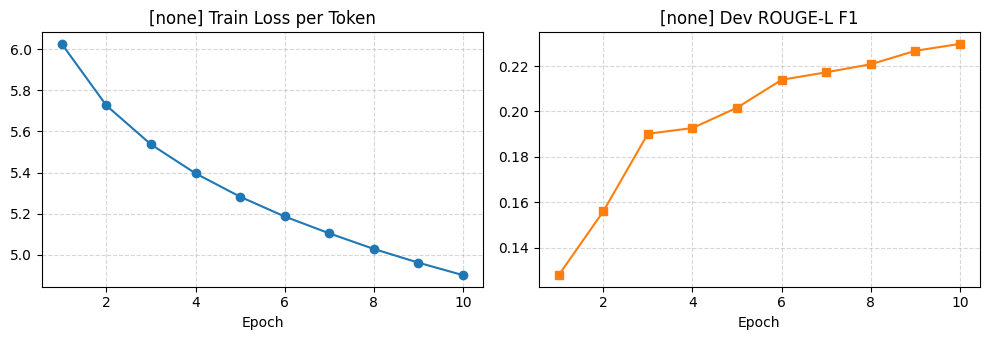

[none] Dev : ROUGE-L F1 = 0.2298 | BLEU = 2.32
[none] Test: ROUGE-L F1 = 0.2346 | BLEU = 2.63
=== 3 câu dịch mẫu trên tập Test [none] ===

Mẫu 1 (ROUGE-L F1 = 1.00)
Câu nguồn      : ( applause )
Câu tham chiếu : ( vỗ tay )
Mô hình dịch   : ( vỗ tay )

Mẫu 2 (ROUGE-L F1 = 0.80)
Câu nguồn      : bg : thank you .
Câu tham chiếu : bg : cảm ơn .
Mô hình dịch   : rl : cảm ơn .

Mẫu 3 (ROUGE-L F1 = 0.00)
Câu nguồn      : vietnamese man cheats , sending staff to be quarantined in his stead
Câu tham chiếu : gã đàn ông việt gian lận , " đánh tráo " nhân viên cách ly thay mình
Mô hình dịch   : <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .


In [18]:
trained_models, all_histories, best_epochs_dict, final_scores = {}, {}, {}, {}

def run_experiment(attn_type, title):
    seed_all(42)
    model = build_seq2seq_model(attn_type)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{title} | Tổng số tham số: {n_params:,}")

    history, best_ep = train_and_validate(model, attn_type)
    trained_models[attn_type] = model
    all_histories[attn_type] = history
    best_epochs_dict[attn_type] = best_ep

    plot_single_learning_curve(history, attn_type)
    final_scores[attn_type] = report_scores(model, attn_type)
    return model

model_b1 = run_experiment('none', 'Bài 1 (không attention)')
SAMPLE_TEST_INDICES = select_sample_indices(model_b1, filtered['test'])
samples_b1 = inspect_sample_translations(model_b1, filtered['test'], SAMPLE_TEST_INDICES, 'none')

#### Nhận xét Bài 1: Seq2Seq không attention

**1. Đồ thị huấn luyện**
- Train loss giảm đều, không dao động hay tăng lại, nên quá trình huấn luyện ổn định
- ROUGE-L trên dev tăng liên tục và epoch tốt nhất là epoch cuối. Có thể cải thiện thêm nếu train lâu hơn
- Không có dấu hiệu overfit: train loss giảm thì dev cũng tăng theo.
- Bài 1 không dùng Attention nên loss giảm chậm nhất vì toàn bộ câu nguồn bị nén vào một vector cố định

**2. Dev và Test**
- ROUGE-L dev và test chênh nhau không quá nhiều, nên mô hình tổng quát hóa ổn và việc chọn epoch theo dev không làm lệch kết quả.
- Đây là mức điểm thấp nhất trong 3 bài.
- BLEU thấp hơn ROUGE-L rất nhiều. Đối với bài toán dịch máy thì ROUGH-L không thể nào đánh giá hiệu quả hơn BLEU vì nó chỉ chấm điểm dựa trên vị trí tương đối thay vì vị trí theo thứ tự như là BLEU. Đồng thời, BLEU còn có cơ chế chấm điểm theo N-gram và phạt nên kết quả sẽ bị kéo xuống nhiều lần. Dựa trên kết quả thì mô hình chỉ mới học được các từ phổ biến và cấu trúc chung, chưa dịch được các nội dung phức tạp
- BLEU được tính trên thang 0-100, có nghĩa là hiện tại mô hình còn quá yếu


**3. Ba câu dịch mẫu**
- **Mẫu 1**: dịch đúng hoàn toàn. Đây là mẫu câu rất ngắn và lặp lại nhiều lần trong dữ liệu, nên mô hình ghi nhớ được.
- **Mẫu 2**: dịch đúng phần nội dung ("cảm ơn") và dấu câu, nhưng sai ký hiệu viết tắt (`bg` thành `rl`). Ký hiệu này hiếm nên bị đổi thành `<unk>`, mô hình không có thông tin để chép lại.
- **Mẫu 3**: toàn bộ đầu ra là `<unk>`. Câu nguồn chứa nhiều từ hiếm (bị `<unk>` ở đầu vào), câu dài làm nút thắt thông tin nặng hơn, và từ điển đích bị cắt nên nhiều từ cần dùng không có sẵn. Khi thiếu thông tin, mô hình chọn token phổ biến nhất.
- Lưu ý: hai mẫu "đúng" được chọn theo ROUGE-L cao nhất nên đều là câu ngắn, dễ và không đại diện cho khả năng dịch câu thực tế.

#### Bài 2: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

#### Yêu cầu đầu ra:
* Chỉ số, đồ thị huấn luyện và 3 câu dịch mẫu + nhận xét tương tự Bài 1
* Trực quan hóa Attention Heatmap: Vẽ 3 heatmap tương ứng với 3 câu dịch mẫu ở trên (trục tung là các token tiếng Việt sinh ra tính đến <eos>, trục hoành là các token tiếng Anh nguồn tính đến <eos>), kiểm tra tổng trọng số mỗi hàng bằng 1.0

#### [Bài 2] 14. Huấn luyện, Đánh giá & Vẽ Heatmap Bahdanau (bahdanau)

Bài 2 (Bahdanau attention) | Tổng số tham số: 8,025,763
[bahdanau] Epoch  1/10 | Train Loss: 6.0413 | Dev ROUGE-L: 0.1413 | Dev BLEU: 0.17 | Time: 111.2s
[bahdanau] Epoch  2/10 | Train Loss: 5.6456 | Dev ROUGE-L: 0.1985 | Dev BLEU: 1.17 | Time: 110.9s
[bahdanau] Epoch  3/10 | Train Loss: 5.3636 | Dev ROUGE-L: 0.2175 | Dev BLEU: 1.64 | Time: 110.5s
[bahdanau] Epoch  4/10 | Train Loss: 5.1682 | Dev ROUGE-L: 0.2445 | Dev BLEU: 2.39 | Time: 110.9s
[bahdanau] Epoch  5/10 | Train Loss: 4.9980 | Dev ROUGE-L: 0.2525 | Dev BLEU: 2.69 | Time: 110.9s
[bahdanau] Epoch  6/10 | Train Loss: 4.8640 | Dev ROUGE-L: 0.2721 | Dev BLEU: 3.50 | Time: 110.7s
[bahdanau] Epoch  7/10 | Train Loss: 4.7457 | Dev ROUGE-L: 0.2755 | Dev BLEU: 3.51 | Time: 111.1s
[bahdanau] Epoch  8/10 | Train Loss: 4.6416 | Dev ROUGE-L: 0.2856 | Dev BLEU: 3.85 | Time: 111.4s
[bahdanau] Epoch  9/10 | Train Loss: 4.5577 | Dev ROUGE-L: 0.2948 | Dev BLEU: 4.31 | Time: 111.0s
[bahdanau] Epoch 10/10 | Train Loss: 4.4777 | Dev ROUGE-L: 0.2

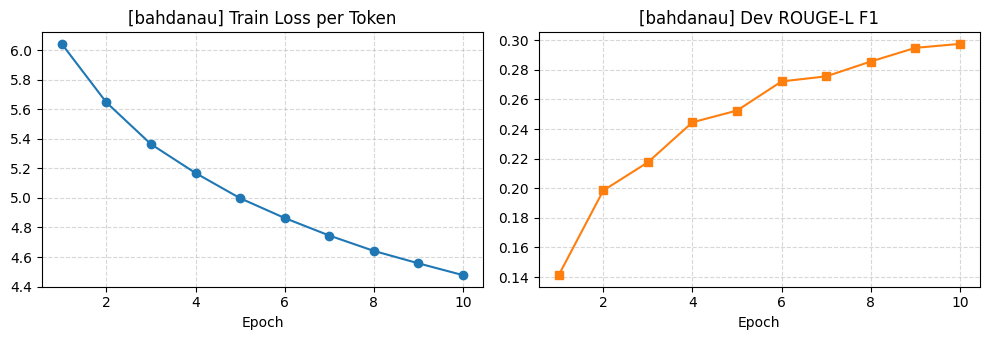

[bahdanau] Dev : ROUGE-L F1 = 0.2975 | BLEU = 4.22
[bahdanau] Test: ROUGE-L F1 = 0.3138 | BLEU = 5.65
=== 3 câu dịch mẫu trên tập Test [bahdanau] ===

Mẫu 1 (ROUGE-L F1 = 1.00)
Câu nguồn      : ( applause )
Câu tham chiếu : ( vỗ tay )
Mô hình dịch   : ( vỗ tay )

Mẫu 2 (ROUGE-L F1 = 0.80)
Câu nguồn      : bg : thank you .
Câu tham chiếu : bg : cảm ơn .
Mô hình dịch   : tr : cảm ơn .

Mẫu 3 (ROUGE-L F1 = 0.07)
Câu nguồn      : vietnamese man cheats , sending staff to be quarantined in his stead
Câu tham chiếu : gã đàn ông việt gian lận , " đánh tráo " nhân viên cách ly thay mình
Mô hình dịch   : người người <unk> <unk> , <unk> <unk> <unk> <unk> <unk> <unk> <unk> .
Mẫu 1: tổng trọng số mỗi hàng nằm trong [1.0000, 1.0000] -> OK


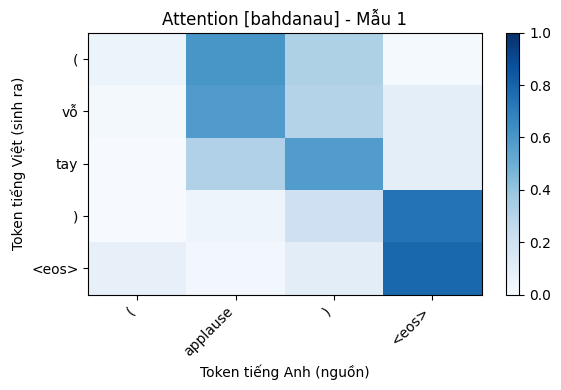

Mẫu 2: tổng trọng số mỗi hàng nằm trong [1.0000, 1.0000] -> OK


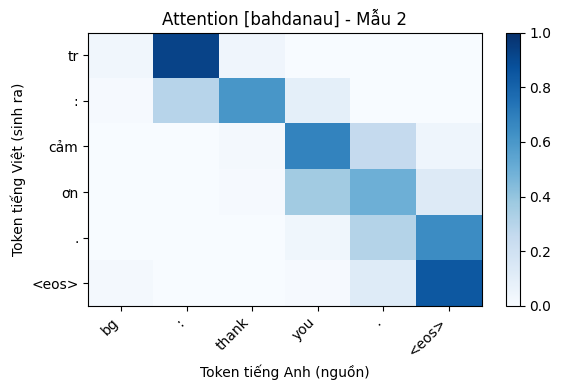

Mẫu 3: tổng trọng số mỗi hàng nằm trong [1.0000, 1.0000] -> OK


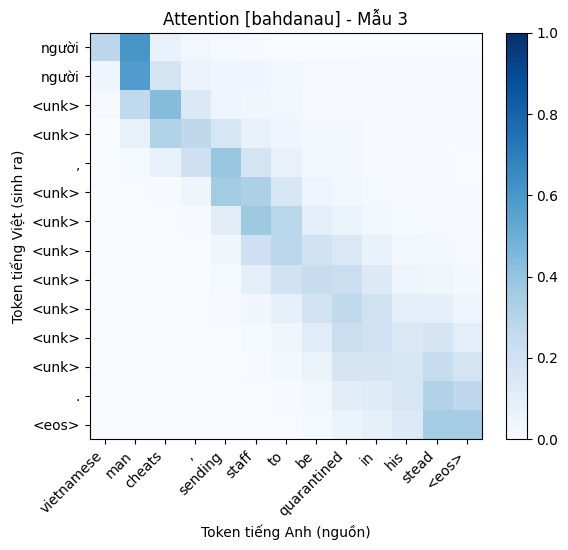

In [19]:
model_b2 = run_experiment('bahdanau', 'Bài 2 (Bahdanau attention)')
samples_b2 = inspect_sample_translations(model_b2, filtered['test'], SAMPLE_TEST_INDICES, 'bahdanau')
plot_sample_heatmaps(samples_b2, 'bahdanau')

#### Nhận xét Bài 2: Bahdanau Attention

**1. Đồ thị huấn luyện**
- Train loss giảm nhanh và thấp hơn Bài 1 ở mọi epoch. Điều này cho thấy attention giúp mô hình học hiệu quả hơn.
- ROUGE-L dev tăng nhanh ngay từ những epoch đầu và vẫn còn tăng ở epoch cuối, nên mô hình vẫn **chưa hội tụ**. Thêm epoch có thể cải thiện tiếp.
- Đường cong của Bahdanau nằm trên cùng, hội tụ nhanh nhất trong ba mô hình.
- Không có dấu hiệu overfit.

**2. Kết quả Dev và Test**
- Cải thiện rõ rệt so với Bài 1 ở cả ROUGE-L lẫn BLEU, nên việc cho Decoder "nhìn lại" câu nguồn là có hiệu quả.
- Dev và test gần nhau (test nhỉnh hơn), nên kết quả ổn định và không bị lệch do chọn epoch trên dev.
- BLEU vẫn thấp: câu dịch đúng ở mức từ và cụm ngắn, chưa chuẩn khi dịch câu.

**3. Ba câu dịch mẫu**
- **Mẫu 1**: đúng hoàn toàn, giống Bài 1.
- **Mẫu 2**: đúng phần "cảm ơn", vẫn sai ký hiệu viết tắt. Mỗi mô hình đoán ra một ký hiệu khác nhau. Đây là lỗi do từ hiếm bị `<unk>`, attention không giải quyết được.
- **Mẫu 3** (câu dài): vẫn sai nhưng đã khá hơn Bài 1. Mô hình sinh được từ "người" và dấu phẩy thay vì chỉ toàn `<unk>`. Phần còn lại vẫn là `<unk>` vì từ vựng nguồn và đích đều thiếu từ hiếm. Có hiện tượng lặp từ ("người người") do mô hình không có cơ chế tránh lặp.

**4. Heatmap Attention** (tổng mỗi hàng bằng 1.0, kiểm tra đạt)
- **Mẫu 1**: "vỗ" và "tay" cùng tập trung vào `applause`. Đây là quan hệ một từ Anh sang hai từ Việt, nên attention đã học đúng quan hệ nghĩa. Các token đóng `)` và `<eos>` tập trung vào `<eos>` nguồn, cho thấy mô hình dùng `<eos>` làm tín hiệu kết thúc.
- **Mẫu 2**: có đường chéo khá rõ, nghĩa là mô hình học được thứ tự từ gần như tuần tự giữa Anh và Việt. Đường chéo có xu hướng lệch một vị trí vì Bahdanau dùng trạng thái của bước trước làm query. Ở từ viết tắt, attention không tập trung vào `bg`, phù hợp với việc ký hiệu này không mang thông tin.
- **Mẫu 3**: attention dàn trải, nhạt màu và không rõ điểm nhấn. Mô hình vẫn đi từ trái sang phải theo câu nguồn nhưng không chắc nên dịch gì, đây là nguyên nhân dẫn đến `<unk>` và lặp từ. Chỉ có từ "người" tập trung rõ vào `man`.
- Kết luận: attention chỉ rõ nét ở câu ngắn, câu dài thì mờ. Điều này khớp với chất lượng dịch từng mẫu.

#### Bài 3: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

#### Yêu cầu đầu ra:
* Toàn bộ các chỉ số, đồ thị huấn luyện và 3 câu dịch mẫu + nhận xét tương tự bài 1
* Bảng tổng hợp đối chiếu cả 3 mô hình: Lập bảng so sánh trực tiếp 3 kiến trúc của 3 bài (none, bahdanau, luong) trên các tiêu chí: ROUGE-L dev, ROUGE-L test, Số tham số, Giây/epoch

#### [Bài 3] 15. Huấn luyện & Đánh giá Luong Attention (luong)

Bài 3 (Luong attention) | Tổng số tham số: 7,959,971
[luong   ] Epoch  1/10 | Train Loss: 6.0734 | Dev ROUGE-L: 0.1301 | Dev BLEU: 0.11 | Time: 101.2s
[luong   ] Epoch  2/10 | Train Loss: 5.7382 | Dev ROUGE-L: 0.1692 | Dev BLEU: 0.81 | Time: 101.0s
[luong   ] Epoch  3/10 | Train Loss: 5.5026 | Dev ROUGE-L: 0.1936 | Dev BLEU: 1.21 | Time: 100.6s
[luong   ] Epoch  4/10 | Train Loss: 5.2998 | Dev ROUGE-L: 0.2208 | Dev BLEU: 1.79 | Time: 100.8s
[luong   ] Epoch  5/10 | Train Loss: 5.1162 | Dev ROUGE-L: 0.2355 | Dev BLEU: 2.27 | Time: 100.8s
[luong   ] Epoch  6/10 | Train Loss: 4.9604 | Dev ROUGE-L: 0.2503 | Dev BLEU: 2.84 | Time: 100.8s
[luong   ] Epoch  7/10 | Train Loss: 4.8296 | Dev ROUGE-L: 0.2664 | Dev BLEU: 3.31 | Time: 101.0s
[luong   ] Epoch  8/10 | Train Loss: 4.7166 | Dev ROUGE-L: 0.2775 | Dev BLEU: 3.62 | Time: 101.8s
[luong   ] Epoch  9/10 | Train Loss: 4.6231 | Dev ROUGE-L: 0.2865 | Dev BLEU: 4.03 | Time: 102.3s
[luong   ] Epoch 10/10 | Train Loss: 4.5282 | Dev ROUGE-L: 0.2905

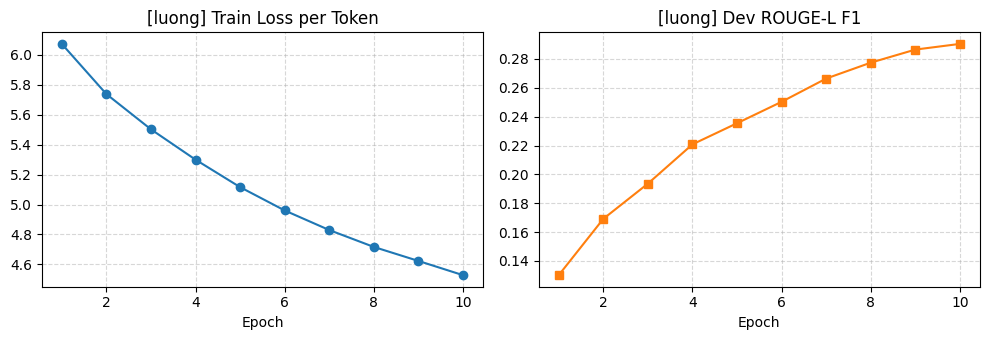

[luong] Dev : ROUGE-L F1 = 0.2905 | BLEU = 4.07
[luong] Test: ROUGE-L F1 = 0.3054 | BLEU = 5.25
=== 3 câu dịch mẫu trên tập Test [luong] ===

Mẫu 1 (ROUGE-L F1 = 1.00)
Câu nguồn      : ( applause )
Câu tham chiếu : ( vỗ tay )
Mô hình dịch   : ( vỗ tay )

Mẫu 2 (ROUGE-L F1 = 0.80)
Câu nguồn      : bg : thank you .
Câu tham chiếu : bg : cảm ơn .
Mô hình dịch   : ng : cảm ơn .

Mẫu 3 (ROUGE-L F1 = 0.00)
Câu nguồn      : vietnamese man cheats , sending staff to be quarantined in his stead
Câu tham chiếu : gã đàn ông việt gian lận , " đánh tráo " nhân viên cách ly thay mình
Mô hình dịch   : <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .


In [20]:
model_b3 = run_experiment('luong', 'Bài 3 (Luong attention)')
samples_b3 = inspect_sample_translations(model_b3, filtered['test'], SAMPLE_TEST_INDICES, 'luong')

#### Nhận xét Bài 3: Luong Attention

**1. Đồ thị huấn luyện**
- Train loss giảm đều, thấp hơn Bài 1 nhưng cao hơn Bahdanau.
- Ba epoch đầu, ROUGE-L dev gần như bám sát mô hình không attention, sau đó mới tách ra và tăng nhanh. Luong khởi động chậm hơn Bahdanau.
- Như 2 bài kia, thì có thể thêm epochs để cải thiện kết quả
- Không có dấu hiệu overfit.

**2. Kết quả Dev và Test**
- Cải thiện rõ rệt so với Bài 1 và nằm sát dưới Bahdanau ở cả ROUGE-L lẫn BLEU.
- Dev và test gần nhau (test nhỉnh hơn), nên kết quả ổn định.
- BLEU vẫn thấp, cùng nguyên nhân với hai bài trước: dịch đúng từ nhưng chưa trôi chảy.

**3. Ba câu dịch mẫu**
- **Mẫu 1**: đúng hoàn toàn.
- **Mẫu 2**: đúng phần "cảm ơn", sai ký hiệu viết tắt, cùng lỗi từ hiếm như hai bài trước.
- **Mẫu 3** (câu dài): toàn `<unk>` giống Bài 1, kém hơn Bahdanau một chút (Bahdanau sinh được vài từ thật). Mô hình vẫn thất bại ở câu dài chứa nhiều từ hiếm.
- Trong cả ba bài, hai mẫu đầu luôn đúng và mẫu cuối luôn sai, cho thấy điểm yếu chung nằm ở dữ liệu và từ điển (từ hiếm, câu dài) chứ không chỉ ở kiến trúc.

#### [Evaluation] 16. Chấm điểm test & Bảng tổng hợp đánh giá

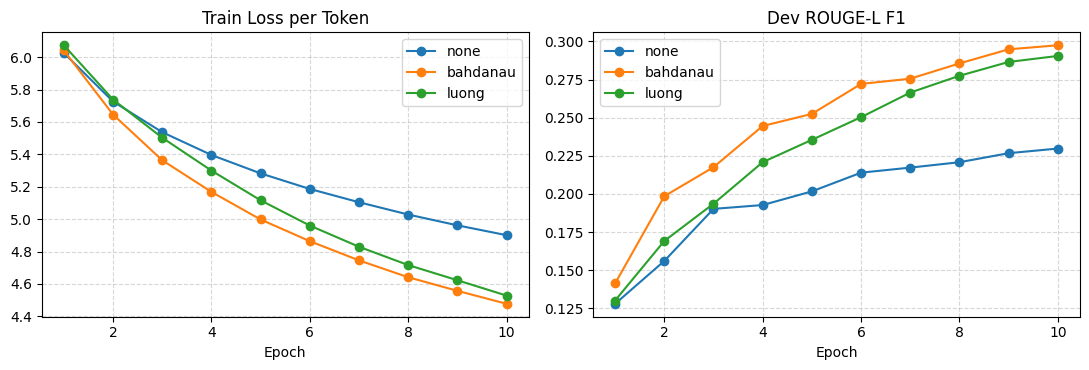

        Mô hình  ROUGE-L dev  ROUGE-L test  BLEU test  Best epoch  Số tham số  Giây/epoch
Không attention       0.2298        0.2346       2.63          10     7500963        70.6
       Bahdanau       0.2975        0.3138       5.65          10     8025763       110.9
          Luong       0.2905        0.3054       5.25          10     7959971       101.2


In [21]:
def plot_combined_curves(histories):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for name, records in histories.items():
        df = pd.DataFrame(records)
        axes[0].plot(df['epoch'], df['train_loss'], marker='o', label=name)
        axes[1].plot(df['epoch'], df['rougeL_f1'], marker='o', label=name)
    axes[0].set_title('Train Loss per Token')
    axes[1].set_title('Dev ROUGE-L F1')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend()
    fig.tight_layout()
    plt.show()

def build_summary_table():
    labels = {'none': 'Không attention', 'bahdanau': 'Bahdanau', 'luong': 'Luong'}
    rows = []
    for key in ['none', 'bahdanau', 'luong']:
        dev, test = final_scores[key]
        rows.append({
            'Mô hình': labels[key],
            'ROUGE-L dev': round(dev['rougeL_f1'], 4),
            'ROUGE-L test': round(test['rougeL_f1'], 4),
            'BLEU test': round(test['bleu'], 2),
            'Best epoch': best_epochs_dict[key],
            'Số tham số': sum(p.numel() for p in trained_models[key].parameters()),
            'Giây/epoch': round(np.mean([e['seconds'] for e in all_histories[key]]), 1)
        })
    table = pd.DataFrame(rows)
    print(table.to_string(index=False))
    return table

plot_combined_curves(all_histories)
summary_df = build_summary_table()

#### Nhận xét bảng tổng hợp: so sánh ba kiến trúc

- **Attention có hiệu quả rõ rệt.** Cả hai mô hình có attention đều vượt mô hình nền ở mọi chỉ số, vì Decoder được tra lại toàn bộ câu nguồn thay vì chỉ dựa vào một vector nén.
- **Bahdanau và Luong khá sát nhau.** Bahdanau nhỉnh hơn nhưng chênh lệch nhỏ. Mỗi mô hình chỉ chạy một lần với một seed, nên chưa đủ cơ sở kết luận chắc chắn cái nào tốt hơn.
- **Có đánh đổi giữa chất lượng và chi phí.** Bahdanau tốn nhiều tham số và thời gian hơn vì tính điểm attention bằng công thức cộng trên toàn bộ câu nguồn ở mỗi bước. Luong rẻ hơn (dùng phép nhân) nhưng kém hơn một chút.
- **Lựa chọn thực tế:** ưu tiên chất lượng thì chọn Bahdanau, ưu tiên tốc độ thì chọn Luong.
- **Hạn chế chung của cả ba:** dữ liệu nhỏ, từ điển bị cắt nên nhiều `<unk>`, chỉ train 10 epoch (cả ba còn đang cải thiện), teacher forcing trộn ngẫu nhiên và giải mã greedy.

#### [Bổ sung] 17. In thử 5 cặp câu mẫu khác trong 3 bài

In [22]:
# Chấm ROUGE-L F1 từng câu trên toàn bộ tập test cho một mô hình
@torch.no_grad()
def per_sentence_rouge(model, test_rows):
    model.eval()
    scores = []
    for start in range(0, len(test_rows), cfg['batch']):
        chunk = test_rows[start:start + cfg['batch']]
        batch = collate_batch(chunk)
        gen_ids, _ = greedy_decode(model, batch['src'].to(device), batch['lengths'], cfg['max_words'] + 1)
        for row, seq in zip(chunk, gen_ids.cpu()):
            hyp = ids_to_text(seq, tgt_itos)
            scores.append(rouge_eval.score(' '.join(row['tgt']), hyp)['rougeL'].fmeasure)
    return np.array(scores)

# Chọn n câu ngẫu nhiên trải đều từ điểm thấp đến cao
def select_spread_indices(models, test_rows, n=5, seed=7):
    avg_score = np.mean([per_sentence_rouge(m, test_rows) for m in models], axis=0)
    order = np.argsort(avg_score)                 
    groups = np.array_split(order, n)            
    rng = np.random.default_rng(seed)
    return [int(rng.choice(g)) for g in groups]   

# Thực thi: 5 câu chung cho cả 3 mô hình
model_names = ['none', 'bahdanau', 'luong']
spread_indices = select_spread_indices([trained_models[k] for k in model_names], filtered['test'])

for name in model_names:
    _ = inspect_sample_translations(trained_models[name], filtered['test'], spread_indices, name)

=== 3 câu dịch mẫu trên tập Test [none] ===

Mẫu 1 (ROUGE-L F1 = 0.09)
Câu nguồn      : it therefore needs to be revised as soon as possible .
Câu tham chiếu : vì thế , cần phải điều chỉnh lại càng sớm càng tốt .
Mô hình dịch   : nó có thể có thể được được nhiều .

Mẫu 2 (ROUGE-L F1 = 0.17)
Câu nguồn      : and there are all these times where crimer , the supercriminal , does all of these tv things .
Câu tham chiếu : và tất cả mọi lúc crimer tên siêu tội phạm , làm mọi thứ trên tv đó .
Mô hình dịch   : và những người có có một , , , , , , là một là một là .

Mẫu 3 (ROUGE-L F1 = 0.26)
Câu nguồn      : he gave them " wool 2 , " which was a little bit longer than the first one , " wool 3 , " which was even longer , culminating in " wool 5 , " which was a 60,000 - word novel .
Câu tham chiếu : ông cho ra đời " wool 2 " , là một tập dài hơn tập đầu tiên chút ít , " wool 3 " , thậm chí còn dài hơn nữa , rồi đỉnh điểm là " wool 5 " , là một tiểu thuyết 60,000 từ .
Mô hình dịch   : ông ta nói 